# Project 1: Wealth Inequality in Denmark
Starter notebook. Add your names, code and interpretations. Keep your simulation module (.py) beside this notebook.

**Group name:**  
**Members:**

The tasks are in the project PDF. [Course plan: deadline and rules](https://github.com/NumEconCopenhagen/ProgEcon-lectures/blob/main/PLAN_autumn26.md#projects-and-exam) · [Hand-in: Dropbox file request](https://www.dropbox.com/request/6cn75p9izf51x3am6kfe) (one `GroupName_P1_v1.zip` per group)

## Download function
`download('FORMUE16', PERCENTIL='*', ...)` asks Statistics Denmark for table FORMUE16. Each keyword is one **variable code** and its value selects the rows you want; `'*'` selects all values. This is the same information as the `variables` list in the Lecture 10 API notebook, written more compactly, and it needs no extra package. The result is a DataFrame with one column per variable and the number in `value`.

To find the codes of another table, open its table information in your browser, for example [FORMUE15](https://api.statbank.dk/v1/tableinfo/FORMUE15?lang=en&format=JSON).

In [ ]:
from io import BytesIO
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def download(table, **selectors):
    """Download a StatBank table as a DataFrame. Each keyword is one variable code; '*' selects all values."""
    url = f'https://api.statbank.dk/v1/data/{table}/CSV'
    params = dict(lang='en', valuePresentation='Code', **selectors)
    response = requests.get(url, params=params, timeout=45)
    response.raise_for_status()
    frame = pd.read_csv(BytesIO(response.content), sep=';', dtype=str, encoding='utf-8-sig')
    frame = frame.rename(columns={frame.columns[-1]: 'value'})
    frame['value'] = pd.to_numeric(frame['value'].str.replace(',', '.', regex=False))
    return frame

settings = dict(PRISENHED='006', ALDER='*', Tid='2024')  # nominal DKK, all age groups, 2024

percentiles = download('FORMUE16', PERCENTIL='*', **settings)
percentiles.head()

,PERCENTIL,PRISENHED,ALDER,TID,value
0,P1,006,1802,2024,-872193
1,P1,006,1829,2024,-474253
2,P1,006,3039,2024,-1184850
3,P1,006,4049,2024,-1212373
4,P1,006,5059,2024,-1007915


## 1.1   Download and Read the Tables
Tasks and hints: PDF Section 1.1.

In [8]:
counts = download('FORMUE15', FORMUE='*', DEFINITION='D20', **settings)
display(counts)

,FORMUE,DEFINITION,PRISENHED,ALDER,TID,value
0,0000M10,D20,006,1802,2024,39466
1,0000M10,D20,006,1829,2024,2345
2,0000M10,D20,006,3039,2024,11605
3,0000M10,D20,006,4049,2024,9680
4,0000M10,D20,006,5059,2024,8096
...,...,...,...,...,...,...
139,0600000,D20,006,5059,2024,72619
140,0600000,D20,006,6069,2024,91456
141,0600000,D20,006,7079,2024,65246
142,0600000,D20,006,8089,2024,23799


## 1.2   Plot the Age Profiles
Tasks and hints: PDF Section 1.2.

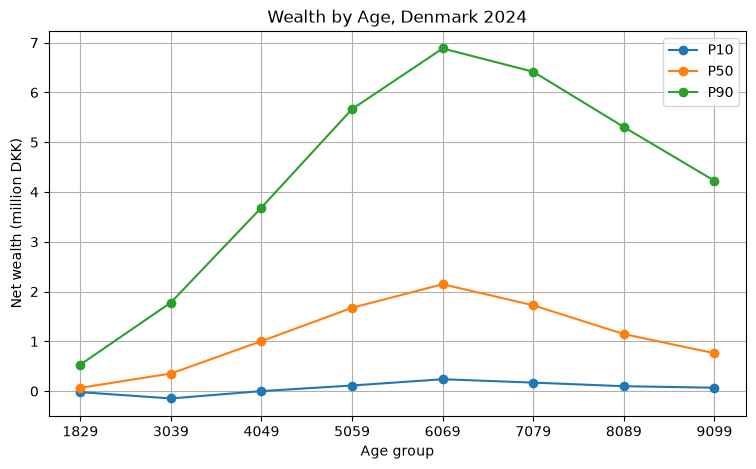

PERCENTIL,10,50,90,Upper gap,Lower gap
ALDER,,,,,
1829,-19750.0,66507.0,532429.0,465922.0,86257.0
3039,-146586.0,353896.0,1780078.0,1426182.0,500482.0
4049,912.0,1004750.0,3688269.0,2683519.0,1003838.0
5059,113324.0,1674287.0,5665305.0,3991018.0,1560963.0
6069,239280.0,2147564.0,6883537.0,4735973.0,1908284.0
7079,171695.0,1724056.0,6415595.0,4691539.0,1552361.0
8089,99096.0,1146853.0,5305568.0,4158715.0,1047757.0
9099,69252.0,761637.0,4225415.0,3463778.0,692385.0


Widest upper gap: 6069 - 4,735,973 DKK
Negative P10: ['1829', '3039']


In [ ]:
# 1.2 Plot the Age Profiles

# Remove all adults and convert P10 -> 10
df = percentiles[percentiles['ALDER'] != '1802'].copy()
df['PERCENTIL'] = df['PERCENTIL'].str.replace('P', '').astype(int)

# Create table with age groups and percentiles
age = df.pivot_table(index='ALDER', columns='PERCENTIL', values='value')

# Plot P10, P50 and P90
age[[10, 50, 90]].div(1e6).plot(marker='o', figsize=(9, 5))

plt.xlabel('Age group')
plt.ylabel('Net wealth (million DKK)')
plt.title('Wealth by Age, Denmark 2024')
plt.legend(['P10', 'P50', 'P90'])
plt.grid()
plt.show()

# Calculate wealth gaps
age['Upper gap'] = age[90] - age[50]
age['Lower gap'] = age[50] - age[10]

display(age[[10, 50, 90, 'Upper gap', 'Lower gap']])

# Answer questions
print('Widest upper gap:', age['Upper gap'].idxmax(),
      '-', f"{age['Upper gap'].max():,.0f}", 'DKK')

print('Negative P10:', age.index[age[10] < 0].tolist())



**Interpretation.** Wealth inequality is highest among the 60–69 age group, where the gap between the 90th percentile and the median is largest. Inequality decreases among older age groups, potentially due to intertemporal consumption, as individuals draw down their accumulated wealth during retirement. However, wealth inequality remains greater among older age groups than among younger adults.

60-69 has the highest upper gap, while 18-29 and 30-39 is negative as borrow money. This also makes inequality measures diificult as we can have negative wealth unlike with income.

## 1.3   Who Has Negative Net Wealth?
Tasks and hints: PDF Section 1.3.

  ALDER        10         50         90  negative_share
0  1829  -19750.0    66507.0   532429.0           12.71
1  3039 -146586.0   353896.0  1780078.0           16.33
2  4049     912.0  1004750.0  3688269.0            9.35
3  5059  113324.0  1674287.0  5665305.0            5.33
4  6069  239280.0  2147564.0  6883537.0            3.16
5  7079  171695.0  1724056.0  6415595.0            3.04
6  8089   99096.0  1146853.0  5305568.0            2.98
7  9099   69252.0   761637.0  4225415.0            1.87


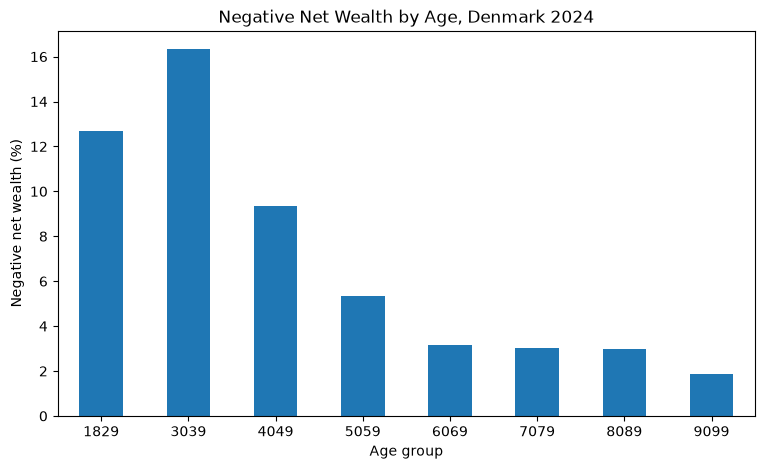

Eight age groups: 4851818
All adults: 4851818


In [12]:

# 1.3 Who Has Negative Net Wealth?

# Wealth brackets below zero
negative = ['0000M10', 'M100M05', 'M050000']

# Count people by age
total = counts.groupby('ALDER')['value'].sum()
neg = counts[counts['FORMUE'].isin(negative)].groupby('ALDER')['value'].sum()

# Share with negative wealth (%)
share = (neg / total * 100).rename('negative_share')

# Merge with percentiles from 1.2
results = pd.merge(
    age[[10, 50, 90]].reset_index(),
    share.reset_index(),
    on='ALDER',
    validate='1:1'
)

print(results.round(2))

# Plot negative wealth share by age (exclude all adults)
results.plot.bar(x='ALDER', y='negative_share', legend=False, figsize=(9, 5))

plt.xlabel('Age group')
plt.ylabel('Negative net wealth (%)')
plt.title('Negative Net Wealth by Age, Denmark 2024')
plt.xticks(rotation=0)
plt.show()

# Check total population
print('Eight age groups:', total.drop('1802').sum())
print('All adults:', total['1802'])



**Interpretation. WThe share of individuals with negative net wealth is highest among the 30–39 age group, at approximately 16.3%. After this age, the share generally decreases, reaching around 1.9% among individuals aged 90 and above.

This contrasts with the median wealth profile in Section 1.2, where median wealth increases with age until 60–69 and then declines. One possible explanation is that younger adults often have more debt relative to their accumulated assets, while older individuals have had more time to accumulate wealth and repay debt.

Finally, the eight age groups sum to 4,851,818 individuals, which matches the published total for all adults. The difference is zero, confirming that the age-group counts are consistent with the overall total.**

## 2.1   Give Everybody Their Age-Group Median
Tasks and hints: PDF Section 2.1.

In [15]:
# Write your simulation function in a .py file next to this notebook and import it here.

# 2.1 Give Everybody Their Age-Group Median

# Population shares by age
age_counts = total.drop('1802')
shares = age_counts / age_counts.sum()

print(shares.round(3))
print('Sum:', shares.sum())


from simulation import simulate

# Simulate 10,000 adults
ages, wealth = simulate(shares.to_numpy(), age.loc[shares.index, 50].to_numpy())

# Compare simulated and actual age shares
comparison = pd.DataFrame({
    'Actual share': shares,
    'Simulated share': [np.mean(ages == j) for j in range(8)]
})

display(comparison.round(3))




ALDER
1829    0.191
3039    0.162
4049    0.146
5059    0.165
6069    0.146
7079    0.120
8089    0.060
9099    0.010
Name: value, dtype: float64
Sum: 1.0


,Actual share,Simulated share
ALDER,,
1829,0.191,0.194
3039,0.162,0.162
4049,0.146,0.144
5059,0.165,0.170
6069,0.146,0.143
7079,0.120,0.118
8089,0.060,0.058
9099,0.010,0.011


**Interpretation.** The simulated age distribution closely matches the actual population shares in Denmark in 2024. For example, the 18–29 age group represents 19.1% of the actual population compared to 19.4% in the simulation.

The small differences arise from random sampling, since we simulate only 10,000 individuals. The population shares sum to 1, confirming that all eight age groups are included.

By assigning each individual the median wealth of their age group, we eliminate wealth inequality within age groups while preserving differences between age groups.

## 2.2   Allow Wealth to Vary Within Each Age Group
Tasks and hints: PDF Section 2.2.

In [22]:

# Convert percentile codes to numbers
df = percentiles[percentiles['ALDER'] != '1802'].copy()
df['PERCENTIL'] = df['PERCENTIL'].str.replace('P', '').astype(int)

# One row per age group, P1 to P99 in columns
table = df.pivot_table(
    index='ALDER',
    columns='PERCENTIL',
    values='value'
)

# Keep the same age order as in 2.1
table = table.loc[shares.index, range(1, 100)]

# Convert to NumPy array
values = table.to_numpy()

# Simulate wealth using the same ages as 2.1
wealth_2 = sim.simulate_wealth(ages, values)

print('Number of adults:', len(wealth_2))
print('Mean wealth:', round(wealth_2.mean()))
print('Median wealth:', round(np.median(wealth_2)))

display(pd.DataFrame({
    'Age group': shares.index.to_numpy()[ages[:10]],
    'Wealth (DKK)': wealth_2[:10]
}))


Number of adults: 10000
Mean wealth: 1713415
Median wealth: 795480


,Age group,Wealth (DKK)
0,6069,199939.0
1,4049,2189575.0
2,7079,2681276.0
3,6069,1841217.0
4,1829,47108.0
5,8089,4268080.0
6,6069,199939.0
7,6069,3506048.0
8,1829,5576.0
9,4049,912.0


## 2.3   Compare Both Economies with Denmark
Tasks and hints: PDF Section 2.3.

In [23]:

# 2.3 Compare Both Economies with Denmark

# Observed Denmark (all adults)
dk = percentiles[percentiles['ALDER'] == '1802'].set_index('PERCENTIL')['value']

dk_negative = counts[
    (counts['ALDER'] == '1802') &
    (counts['FORMUE'].isin(negative))
]['value'].sum() / total['1802'] * 100

# Create comparison table
comparison = pd.DataFrame({
    'P10': [dk['P10'], np.percentile(wealth, 10), np.percentile(wealth_2, 10)],
    'P50': [dk['P50'], np.median(wealth), np.median(wealth_2)],
    'P90': [dk['P90'], np.percentile(wealth, 90), np.percentile(wealth_2, 90)],
    'Negative wealth (%)': [
        dk_negative,
        100 * np.mean(wealth < 0),
        100 * np.mean(wealth_2 < 0)
    ]
}, index=['Observed Denmark', 'Age-group medians', 'Within-age variation'])

# Calculate P90 - P10
comparison['P90 - P10'] = comparison['P90'] - comparison['P10']

# Show table
display(comparison[['P10', 'P50', 'P90', 'P90 - P10', 'Negative wealth (%)']].round(2))

# Fraction of observed wealth gap reproduced
fraction = comparison.loc['Age-group medians', 'P90 - P10'] / comparison.loc['Observed Denmark', 'P90 - P10']

print(f'Fraction of observed gap reproduced: {fraction:.1%}')


,P10,P50,P90,P90 - P10,Negative wealth (%)
Observed Denmark,3386.0,800814.0,4475610.0,4472224.0,8.34
Age-group medians,66507.0,1004750.0,2147564.0,2081057.0,0.00
Within-age variation,6636.0,795480.0,4170986.0,4164350.0,8.08


Fraction of observed gap reproduced: 46.5%


**Interpretation.** The first simulated economy reproduces 46.5% of the observed P90–P10 wealth gap in Denmark. This is because the simulation only captures wealth differences between age groups and ignores inequality within each group. No individuals have negative net wealth because all age-group medians are positive.

The second simulated economy is much closer to the observed Danish wealth distribution. The P90–P10 gap is approximately 4.16 million DKK, compared to 4.47 million DKK in the observed data. The median wealth is also very similar (795,480 DKK compared to 800,814 DKK), and the share with negative net wealth is 8.08%, compared to 8.34% in Denmark.

The remaining differences can be explained by random sampling and the use of published percentile thresholds rather than individuals' exact wealth values.

## 2.4   An Older Denmark
Tasks and hints: PDF Section 2.4.

In [24]:

# 2.4 An Older Denmark

# Move 5 percentage points from ages 18-29 to 70-79
older_shares = shares.copy()
older_shares['1829'] -= 0.05
older_shares['7079'] += 0.05

print(older_shares.round(3))
print('Sum:', older_shares.sum())

# Simulate both economies using the same seed
ages_base, wealth_base = sim.simulate_distribution(shares.to_numpy(), values)
ages_older, wealth_older = sim.simulate_distribution(older_shares.to_numpy(), values)

# Compare the five statistics
comparison_24 = pd.DataFrame({
    'P10': [np.percentile(wealth_base, 10), np.percentile(wealth_older, 10)],
    'P50': [np.median(wealth_base), np.median(wealth_older)],
    'P90': [np.percentile(wealth_base, 90), np.percentile(wealth_older, 90)],
    'Negative wealth (%)': [
        100 * np.mean(wealth_base < 0),
        100 * np.mean(wealth_older < 0)
    ]
}, index=['Original population', 'Older population'])

comparison_24['P90 - P10'] = comparison_24['P90'] - comparison_24['P10']

display(comparison_24[['P10', 'P50', 'P90', 'P90 - P10', 'Negative wealth (%)']].round(2))


ALDER
1829    0.141
3039    0.162
4049    0.146
5059    0.165
6069    0.146
7079    0.170
8089    0.060
9099    0.010
Name: value, dtype: float64
Sum: 1.0


,P10,P50,P90,P90 - P10,Negative wealth (%)
Original population,6636.0,797414.0,4359441.0,4352805.0,7.91
Older population,10570.0,930412.0,4631508.0,4620938.0,7.39


**Interpretation.** Write your answer here.

Data: [StatBank FORMUE16](https://www.statbank.dk/FORMUE16) and [StatBank FORMUE15](https://www.statbank.dk/FORMUE15).